# Exploratory Data Analysis of the NZZ Historical Corpus (1780–1815)

This notebook characterises the page-level metadata of the NZZ huGO archive for the period 1780–1815. It relies exclusively on `data/nzz_scans/index.csv` and therefore runs without any of the PDF scan files being present. Each row of the index describes one newspaper page, including its publication date, issue number, page number, topical labels and the number of characters in the existing huGO OCR text (`ocr_zeichen`). The final section is a placeholder for a visual scan quality assessment that will be completed once a sample of PDFs is available.

## 1. Setup

The cell below imports the required libraries, defines a consistent colour palette for all charts and loads the index file. The repository root is located by searching upwards from the current working directory, so the notebook works regardless of whether it is started from the repository root or from the `notebooks/` folder. The `ausgabe_nr` column is read as a string to preserve its leading zeros.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display


def find_repo_root(start: Path) -> Path:
    """Return the first parent directory of ``start`` that contains ``src/config.py``."""
    for candidate in [start, *start.parents]:
        if (candidate / "src" / "config.py").exists():
            return candidate
    raise FileNotFoundError("Could not locate the repository root from " + str(start))


REPO_ROOT = find_repo_root(Path.cwd().resolve())
INDEX_CSV = REPO_ROOT / "data" / "nzz_scans" / "index.csv"

# Consistent styling: one colour per decade, otherwise a single neutral colour.
sns.set_theme(style="whitegrid", context="notebook")
DECADES = ["1780s", "1790s", "1800s", "1810s"]
DECADE_COLORS = dict(zip(DECADES, sns.color_palette("colorblind", n_colors=len(DECADES))))
NEUTRAL = "#5B6770"
FIGSIZE_SINGLE = (12, 4)
FIGSIZE_DOUBLE = (14, 5)

df = pd.read_csv(INDEX_CSV, dtype={"ausgabe_nr": "string"})
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
display(df.head(3))

# Derived columns used throughout the notebook.
df["datum"] = pd.to_datetime(df["datum"], format="%Y-%m-%d")
df["year"] = df["datum"].dt.year
df["decade"] = (df["year"] // 10 * 10).astype(str) + "s"

Shape: 16,720 rows x 14 columns


,datum,zeitung,ausgabe,ausgabe_nr,seite,ressort,unterressort,media_id,media_pub_id,document_id,np_edition_id,or_file,ocr_zeichen,pdf
0,1780-01-12,NZZ - Neue Zürcher Zeitung,Zürich,01,1,Vermischtes,Vermischtes,14523555,57745904,14523555#SEI,9121,1780-01-12_01-00001.pdf,2987,NZZ_Neue_Zürcher_Zeitung/1780/1780-01-12/01_Zü...
1,1780-01-12,NZZ - Neue Zürcher Zeitung,Zürich,01,2,Vermischtes,Vermischtes,14523556,57745905,14523556#SEI,9121,1780-01-12_01-00002.pdf,4625,NZZ_Neue_Zürcher_Zeitung/1780/1780-01-12/01_Zü...
2,1780-01-12,NZZ - Neue Zürcher Zeitung,Zürich,01,3,Vermischtes,Vermischtes,14523557,57745906,14523557#SEI,9121,1780-01-12_01-00003.pdf,4690,NZZ_Neue_Zürcher_Zeitung/1780/1780-01-12/01_Zü...


## 2. Corpus Overview

An issue is defined throughout this notebook as a unique combination of publication date (`datum`) and issue number (`ausgabe_nr`). A small number of pages have no `ausgabe_nr` value (see Section 7); these are kept as their own group per date rather than being dropped, which is why `dropna=False` is used when grouping.

In [2]:
issues = df.groupby(["datum", "ausgabe_nr"], dropna=False).size().rename("pages").reset_index()

overview = pd.DataFrame(
    {
        "Value": [
            f"{len(df):,}",
            f"{len(issues):,}",
            df["datum"].min().strftime("%Y-%m-%d"),
            df["datum"].max().strftime("%Y-%m-%d"),
            f"{df['year'].nunique()}",
            f"{df['ocr_zeichen'].sum():,}",
            f"{df['ocr_zeichen'].mean():,.0f}",
            f"{df['ocr_zeichen'].median():,.0f}",
        ]
    },
    index=[
        "Total pages",
        "Total issues",
        "First issue date",
        "Last issue date",
        "Years covered",
        "Total OCR characters (ocr_zeichen)",
        "Mean OCR characters per page",
        "Median OCR characters per page",
    ],
)
display(overview)

,Value
Total pages,"16,720"
Total issues,"3,874"
First issue date,1780-01-12
Last issue date,1815-12-29
Years covered,36
Total OCR characters (ocr_zeichen),"83,176,749"
Mean OCR characters per page,"4,975"
Median OCR characters per page,"5,114"


## 3. Temporal Coverage

The left chart shows the number of pages per year and the right chart the number of issues per year, both coloured by decade. Outside of 1799, the corpus is very evenly distributed, with roughly 410 to 520 pages and 102 to 107 issues per year. The year 1799 stands out with 872 pages, about twice the usual volume, and is annotated in the left chart. The right chart shows that this peak is driven by roughly twice the usual number of issues rather than by longer issues, which points to an increased publication frequency during the War of the Second Coalition, when Zurich was a theatre of war. Since 1799 alone contributes about 5% of all pages, it should be kept in mind when sampling pages for OCR evaluation.

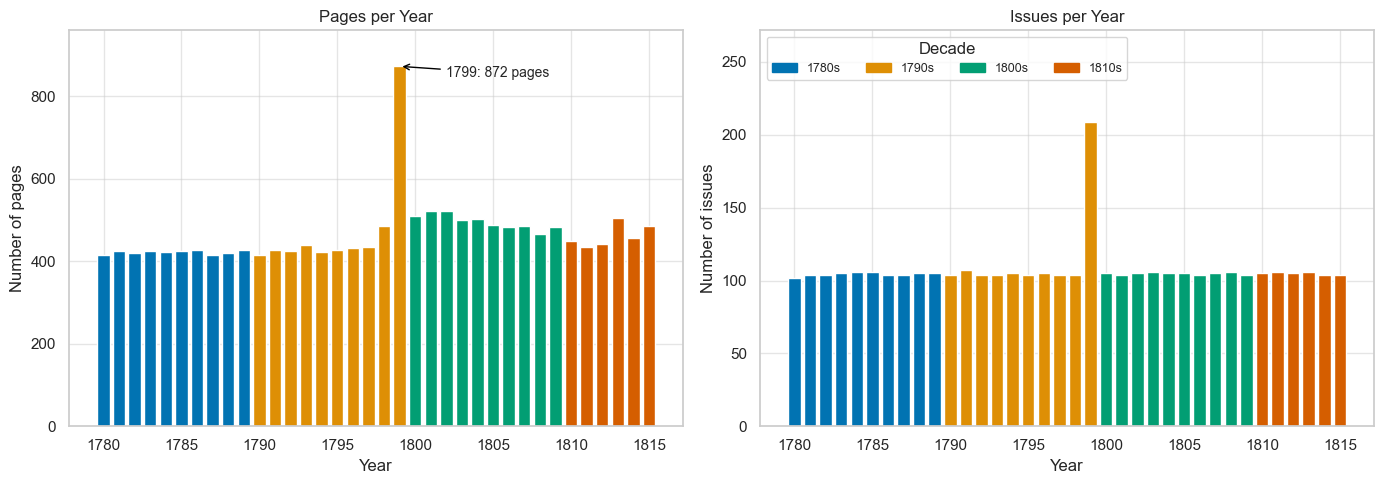

In [3]:
year_decade = df.drop_duplicates("year").set_index("year")["decade"].sort_index()
pages_per_year = df.groupby("year").size().reindex(year_decade.index)
issues_per_year = issues.groupby(issues["datum"].dt.year).size().reindex(year_decade.index)
bar_colors = [DECADE_COLORS[d] for d in year_decade]

fig, (ax_pages, ax_issues) = plt.subplots(1, 2, figsize=FIGSIZE_DOUBLE)

ax_pages.bar(pages_per_year.index, pages_per_year.values, color=bar_colors)
ax_pages.set_title("Pages per Year")
ax_pages.set_xlabel("Year")
ax_pages.set_ylabel("Number of pages")
peak_year = pages_per_year.idxmax()
peak_value = pages_per_year.max()
ax_pages.annotate(
    f"{peak_year}: {peak_value:,} pages",
    xy=(peak_year, peak_value),
    xytext=(peak_year + 3, peak_value * 0.97),
    arrowprops=dict(arrowstyle="->", color="black"),
    fontsize=10,
)
ax_pages.set_ylim(0, peak_value * 1.1)

ax_issues.bar(issues_per_year.index, issues_per_year.values, color=bar_colors)
ax_issues.set_title("Issues per Year")
ax_issues.set_xlabel("Year")
ax_issues.set_ylabel("Number of issues")
ax_issues.set_ylim(0, issues_per_year.max() * 1.3)

handles = [plt.Rectangle((0, 0), 1, 1, color=DECADE_COLORS[d]) for d in DECADES]
ax_issues.legend(handles, DECADES, title="Decade", loc="upper left", ncols=4, fontsize=9)
fig.tight_layout()
display(fig)
plt.close(fig)

## 4. Issue Structure

The chart below shows how many pages each issue contains. The overwhelming majority of issues consist of four pages, which corresponds to a single folded sheet. Six- and eight-page issues occur regularly, while issues with one to three pages or with ten to twelve pages are rare and may indicate supplements, incomplete digitisation or merged issues. Throughout the period the newspaper was published two to three times per week, which is consistent with the roughly 100 to 150 issues per year visible in Section 3.

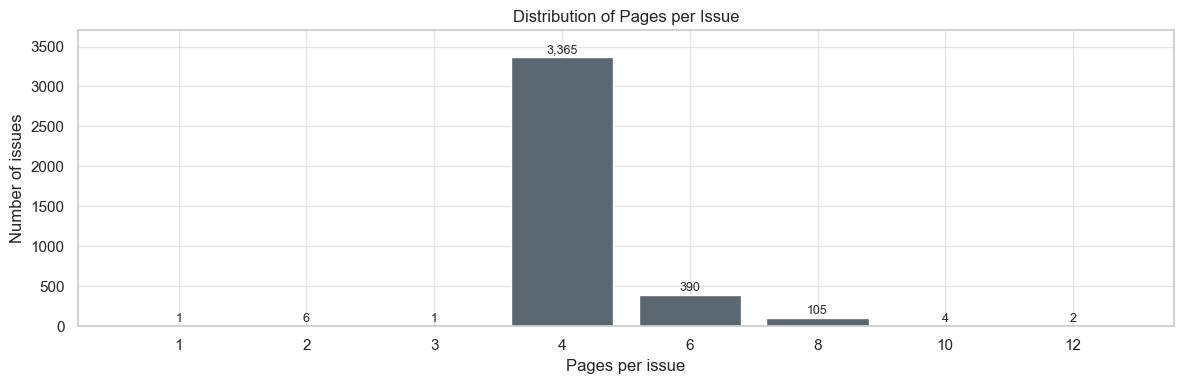

pages_per_issue,1,2,3,4,6,8,10,12
issues,1,6,1,3365,390,105,4,2


In [4]:
pages_per_issue = issues["pages"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=FIGSIZE_SINGLE)
ax.bar(pages_per_issue.index.astype(str), pages_per_issue.values, color=NEUTRAL)
for x, y in zip(pages_per_issue.index.astype(str), pages_per_issue.values):
    ax.annotate(f"{y:,}", xy=(x, y), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
ax.set_title("Distribution of Pages per Issue")
ax.set_xlabel("Pages per issue")
ax.set_ylabel("Number of issues")
ax.set_ylim(0, pages_per_issue.max() * 1.1)
fig.tight_layout()
display(fig)
plt.close(fig)

display(pages_per_issue.rename_axis("pages_per_issue").rename("issues").to_frame().T)

## 5. OCR Character Count Distribution

The `ocr_zeichen` field counts the characters in the existing huGO OCR text of each page. It is a rough proxy for how much text the OCR engine was able to extract and therefore for page density and legibility. The histogram shows the distribution across all pages, and the box plot compares the four decades.

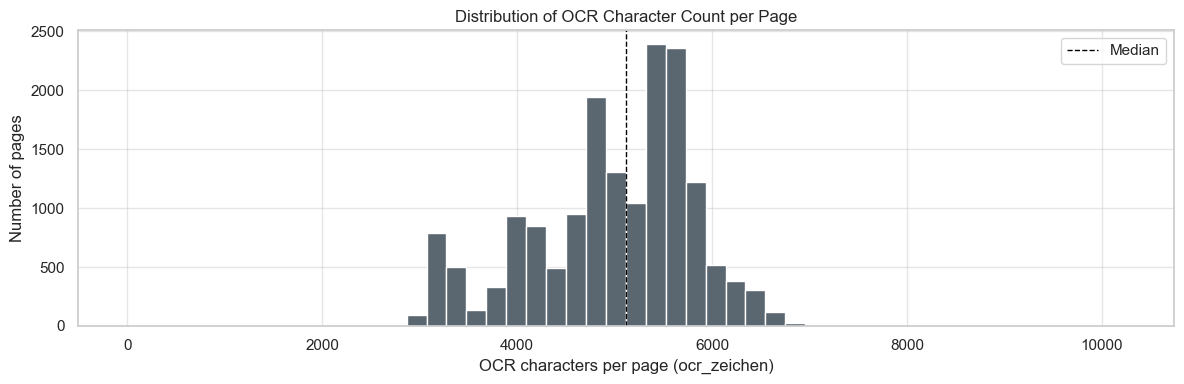

In [5]:
fig, ax = plt.subplots(figsize=FIGSIZE_SINGLE)
ax.hist(df["ocr_zeichen"], bins=50, color=NEUTRAL, edgecolor="white")
ax.axvline(df["ocr_zeichen"].median(), color="black", linestyle="--", linewidth=1, label="Median")
ax.set_title("Distribution of OCR Character Count per Page")
ax.set_xlabel("OCR characters per page (ocr_zeichen)")
ax.set_ylabel("Number of pages")
ax.legend()
fig.tight_layout()
display(fig)
plt.close(fig)

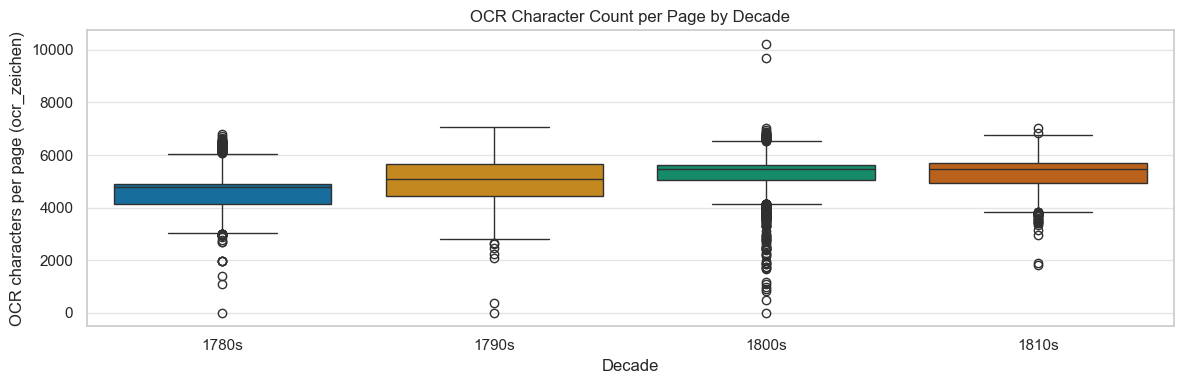

,pages,median,mean,pages_below_1000
decade,,,,
1780s,4217,4773,4492,1
1790s,4775,5082,4974,2
1800s,4958,5451,5224,5
1810s,2770,5469,5261,0


Pages with fewer than 1000 characters: 8 (0.05%)


In [6]:
fig, ax = plt.subplots(figsize=FIGSIZE_SINGLE)
sns.boxplot(
    data=df,
    x="decade",
    y="ocr_zeichen",
    hue="decade",
    order=DECADES,
    hue_order=DECADES,
    palette=DECADE_COLORS,
    legend=False,
    ax=ax,
)
ax.set_title("OCR Character Count per Page by Decade")
ax.set_xlabel("Decade")
ax.set_ylabel("OCR characters per page (ocr_zeichen)")
fig.tight_layout()
display(fig)
plt.close(fig)

LOW_THRESHOLD = 1000
decade_stats = (
    df.groupby("decade")["ocr_zeichen"]
    .agg(pages="size", median="median", mean="mean")
    .reindex(DECADES)
    .assign(**{f"pages_below_{LOW_THRESHOLD}": df[df["ocr_zeichen"] < LOW_THRESHOLD].groupby("decade").size()})
    .fillna(0)
    .astype(int)
)
display(decade_stats)

n_low = int((df["ocr_zeichen"] < LOW_THRESHOLD).sum())
print(f"Pages with fewer than {LOW_THRESHOLD} characters: {n_low} ({n_low / len(df):.2%})")

The median character count rises steadily from 4,773 in the 1780s to 5,082 in the 1790s, 5,451 in the 1800s and 5,469 in the 1810s, which suggests denser typesetting or more legible print in later decades. Pages with fewer than 1,000 characters are extremely rare: only 8 pages in the entire corpus fall below this threshold, which corresponds to 0.05% of all pages. Such pages are likely to be blank, damaged or mostly non-textual and can be reviewed individually rather than treated as a systematic quality problem.

## 6. Ressort / Topical Metadata

The `ressort` field is intended to assign each page to a newspaper section. Empty values are shown as a separate category in the chart below.

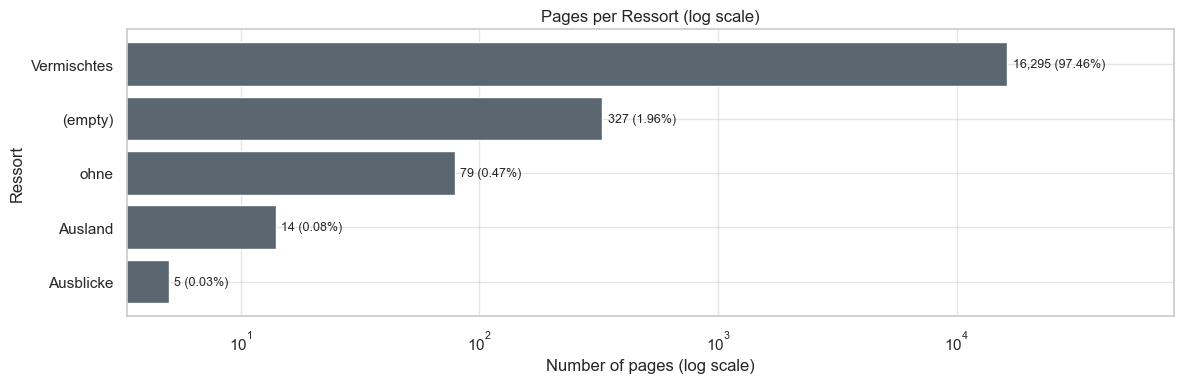

In [7]:
ressort_counts = df["ressort"].fillna("(empty)").value_counts()

fig, ax = plt.subplots(figsize=FIGSIZE_SINGLE)
ax.barh(ressort_counts.index[::-1], ressort_counts.values[::-1], color=NEUTRAL)
for y, x in enumerate(ressort_counts.values[::-1]):
    ax.annotate(f"{x:,} ({x / len(df):.2%})", xy=(x, y), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
ax.set_xscale("log")
ax.set_title("Pages per Ressort (log scale)")
ax.set_xlabel("Number of pages (log scale)")
ax.set_ylabel("Ressort")
ax.set_xlim(right=ressort_counts.max() * 5)
fig.tight_layout()
display(fig)
plt.close(fig)

Almost all pages, 97.5% of the corpus, are labelled "Vermischtes" (miscellaneous), and a further 2% have an empty ressort. The remaining labels ("ohne", "Ausland" and "Ausblicke") together cover fewer than 100 pages. This confirms that no useful topical subdivision exists for this period, which is consistent with the decision to treat the page as the atomic retrieval unit without article or section segmentation. A logarithmic axis is used so that the small categories remain visible next to the dominant one.

## 7. Missing Data Audit

The table below counts, for every column, the values that are null and the values that are present but consist only of whitespace. Rows with missing values are highlighted.

In [8]:
missing = pd.DataFrame(
    {
        "null": df.isna().sum(),
        "empty_string": df.apply(lambda s: s.astype("string").str.strip().eq("").sum()),
    }
)
missing["total_missing"] = missing["null"] + missing["empty_string"]
missing["pct_missing"] = (missing["total_missing"] / len(df) * 100).round(2)


def highlight_missing(row: pd.Series) -> list[str]:
    """Return a background style for rows that contain missing values."""
    style = "background-color: #FCE8B2" if row["total_missing"] > 0 else ""
    return [style] * len(row)


display(missing.style.apply(highlight_missing, axis=1).format({"pct_missing": "{:.2f}"}))

,null,empty_string,total_missing,pct_missing
datum,0,0,0,0.00
zeitung,0,0,0,0.00
ausgabe,0,0,0,0.00
ausgabe_nr,104,0,104,0.62
seite,0,0,0,0.00
ressort,327,0,327,1.96
unterressort,327,0,327,1.96
media_id,0,0,0,0.00
media_pub_id,0,0,0,0.00
document_id,0,0,0,0.00


The `pdf` field, which holds the relative path to each scan, is complete with no missing values, so every page can in principle be linked to its scan file. The `ocr_zeichen` field is also complete. The `ressort` and `unterressort` fields each have 327 empty rows, which matches the empty category in Section 6. In addition, `ausgabe_nr` is missing for 104 pages; these pages use a different file naming scheme in `or_file` (for example `nzz_17800503_0_0_1.pdf`) and were grouped as separate issues by date in Sections 2 to 4.

## 8. Scan Quality Assessment

This section inspects a small sample of scan PDFs stored next to `index.csv` in `data/nzz_scans/`. The sample consists of one complete four-page issue per decade (22 January 1780, 6 March 1790, 2 May 1800 and 29 June 1810), where each PDF file contains a single newspaper page. To keep the comparison balanced, the grid below shows the front page of each issue, which is the lowest page number found for that decade, rendered at 72 DPI. The decade is looked up in `index.csv` via the `or_file` column, and the OCR character count of each page is included in the subplot title for reference. Rendering requires `pdf2image` together with the poppler command-line tools (`brew install poppler` on macOS).

In [ ]:
from pdf2image import convert_from_path

SCAN_DIR = INDEX_CSV.parent
RENDER_DPI = 72

pdf_paths = sorted(SCAN_DIR.glob("**/*.pdf"))
print(f"PDF files found: {len(pdf_paths)}")

page_meta = df.set_index("or_file")[["decade", "ocr_zeichen"]]
scan_sample = pd.DataFrame(
    {
        "path": pdf_paths,
        "stem": [p.stem for p in pdf_paths],
        "decade": [page_meta["decade"].get(p.name, f"{p.stem[:3]}0s") for p in pdf_paths],
        "ocr_zeichen": [page_meta["ocr_zeichen"].get(p.name, pd.NA) for p in pdf_paths],
    }
)
display(scan_sample.groupby("decade")["stem"].agg(["count", "min"]).rename(columns={"min": "front_page"}))

# One page per decade: the lowest page number, i.e. the front page of the sampled issue.
front_pages = scan_sample.sort_values("stem").groupby("decade").head(1).sort_values("decade").reset_index(drop=True)

n_pages = len(front_pages)
if n_pages == 0:
    print("No PDF scans found next to index.csv; skipping the scan grid.")
else:
    n_rows, n_cols = (2, 2) if n_pages == 4 else (1, n_pages)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 10), squeeze=False)
    for ax, page in zip(axes.flat, front_pages.itertuples()):
        image = convert_from_path(page.path, dpi=RENDER_DPI, first_page=1, last_page=1)[0]
        ax.imshow(image, cmap="gray")
        ax.set_title(f"{page.stem} ({page.decade}, {page.ocr_zeichen:,} OCR characters)", fontsize=11)
        ax.axis("off")
    for ax in list(axes.flat)[n_pages:]:
        ax.axis("off")
    fig.suptitle(f"Front Page Scans per Decade ({RENDER_DPI} DPI)", fontsize=14)
    fig.tight_layout()
    display(fig)
    plt.close(fig)

### Observations per decade

The observations below are based on the four front pages shown above, which were additionally checked at a higher rendering resolution to confirm details that are hard to see at 72 DPI. All four scans appear to have been strongly contrast-enhanced or partly binarised during digitisation, so the paper itself is rendered almost white and genuine paper discolouration cannot be judged from these images.

**1780s (1780-01-22).** This is the cleanest page of the sample. The ink is dark and fairly even, and the Fraktur letterforms are crisp and fully legible across both columns. Faint mirrored text from the reverse side shows through in the upper part of the page around the masthead, but it does not reach into the body text. The margins are intact, and the only damage is a thin dark scan border along the right and bottom edges.

**1790s (1790-03-06).** The ink is heavier and less even than in 1780, with several lines in the lower left column appearing bold and slightly smeared. Bleed-through is clearly visible as grey mirrored text in the top margin and on both sides of the masthead, and light grey speckle covers the left margin. A narrow dark strip runs along the left edge of the page, most likely the binding or the page edge, but it does not cut into the text. The body text remains legible, although individual characters in the heavily inked lines start to merge.

**1800s (1800-05-02).** This issue uses a different masthead without the post-rider woodcut and adds a one-line table of contents below the title. Inking varies strongly from line to line: some lines are heavy and bold while others are noticeably lighter, and a grey, blurred band runs across the middle of the right column where the text looks smudged. A dark vertical shadow runs along the left edge and widens into a dark corner at the bottom left. Legibility is still good for most of the page, but the smudged band and the uneven inking are likely to cause localised OCR errors.

**1810s (1810-06-29).** The most striking feature is a large octagonal library or ownership stamp in the top right corner that overlaps the last letters of the masthead and the year. The body text is very heavily inked, with many words in the left column printed as thick black blotches, and the small-type imprint line below the masthead is partly filled in. There is little visible bleed-through and the margins are undamaged apart from a narrow dark border on the left. The text is legible to a human reader, but the over-inking makes stroke-level detail difficult to resolve, especially in the smaller fonts.

### Summary across decades

The sample does not show the expected pattern of older issues being more degraded. In fact, the 1780 front page is the cleanest of the four, while the later pages show progressively more uneven and heavier inking, smudged regions and, in 1810, a stamp overlapping the masthead. The dominant quality problems in this sample are therefore related to printing and scanning (over-inking, uneven ink, edge shadows and bleed-through) rather than to physical damage such as tears or missing margins, which none of the four pages show. This agrees with the very small number of low-character-count pages found in Section 5. The rising median OCR character count across decades is therefore more likely to reflect denser typesetting, such as the added table-of-contents lines in 1800 and 1810, than better print quality. Because each decade is represented by a single issue, these observations should be treated as indicative only and confirmed on a larger stratified sample before they inform preprocessing decisions such as binarisation thresholds or stamp removal.